In [27]:
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import ollama

from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# sklearn 1.9 deprecates SVC(probability=True); it still works and matches the team's setup
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

RANDOM_SEED = 42
EMBED_MODEL = "embeddinggemma-2:270m"
THRESHOLD = 0.5  # P(AI) >= 0.5 -> predicted AI

train_df = pd.read_csv("./data/train.csv")
print(train_df.shape, train_df["label"].value_counts().to_dict())
# print("test.csv columns:", list(pd.read_csv("./data/test.csv", nrows=1).columns), "(no label column)")

(10000, 3) {0: 5000, 1: 5000}


In [28]:
# embed training texts
def embed_texts(texts, model=EMBED_MODEL, batch_size=32):
    """Embed texts with Ollama in small batches (same approach as lr.ipynb)."""
    texts = np.asarray(texts, dtype=str).tolist()
    vectors = []
    for start in range(0, len(texts), batch_size):
        response = ollama.embed(model=model, input=texts[start : start + batch_size])
        vectors.extend(response["embeddings"])
    return np.asarray(vectors, dtype=np.float32)


CACHE_PATH = "./data/train_embeddinggemma2_270m.npy"

if os.path.exists(CACHE_PATH):
    X = np.load(CACHE_PATH)
    print(f"Loaded cached embeddings from {CACHE_PATH}")
else:
    start_time = time.time()
    X = embed_texts(train_df["text"])
    np.save(CACHE_PATH, X)
    print(f"Embedding time: {time.time() - start_time:.1f} seconds")

assert len(X) == len(train_df)
print(X.shape)

Loaded cached embeddings from ./data/train_embeddinggemma2_270m.npy
(10000, 768)


In [29]:
# train model on the whole training set
y = train_df["label"].to_numpy()
indices = np.arange(len(train_df))

X_train = X
y_train = y

model = SVC(kernel="poly", C=10.0, probability=True, random_state=RANDOM_SEED)

start_time = time.time()
model.fit(X_train, y_train)
print(f"Training time: {time.time() - start_time:.1f} seconds")

Training time: 59.5 seconds


In [30]:
print(X_train.shape, y_train.shape)

(10000, 768) (10000,)


In [31]:
# embed test texts

test_df = pd.read_csv("./data/test.csv")

def embed_texts(texts, model=EMBED_MODEL, batch_size=32):
    """Embed texts with Ollama in small batches (same approach as lr.ipynb)."""
    texts = np.asarray(texts, dtype=str).tolist()
    vectors = []
    for start in range(0, len(texts), batch_size):
        response = ollama.embed(model=model, input=texts[start : start + batch_size])
        vectors.extend(response["embeddings"])
    return np.asarray(vectors, dtype=np.float32)


CACHE_PATH = "./data/test_embeddinggemma2_270m.npy"

if os.path.exists(CACHE_PATH):
    X = np.load(CACHE_PATH)
    print(f"Loaded cached embeddings from {CACHE_PATH}")
else:
    start_time = time.time()
    X = embed_texts(test_df["text"])
    np.save(CACHE_PATH, X)
    print(f"Embedding time: {time.time() - start_time:.1f} seconds")

assert len(X) == len(test_df)
print(X.shape)

Loaded cached embeddings from ./data/test_embeddinggemma2_270m.npy
(3000, 768)


In [32]:
# predict and save submission.csv

submission_df = test_df[["id"]].copy()
submission_df["label"] = model.predict_proba(X)[:, 1]
submission_df.to_csv("./submission.csv", index=False)

<Axes: >

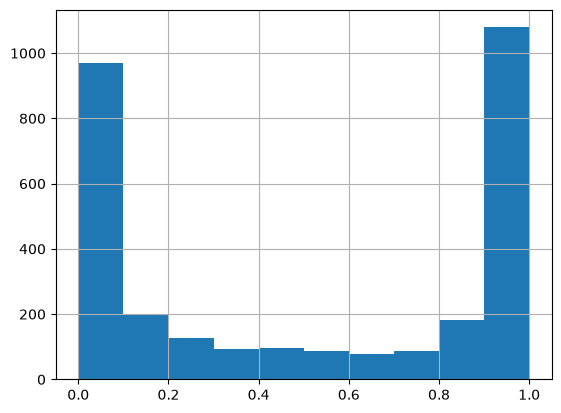

In [33]:
# plot historgram over submission_df["label"], round to 2 digits
submission_df["label"].round(2).hist()